<p style="text-align:center">
    <a href="https://skills.network" target="_blank">
    <img src="https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/assets/logos/SN_web_lightmode.png" width="200" alt="Skills Network Logo"  />
    </a>
</p>


# **Understanding How Developer Survey Data Is Distributed**
**IBM Skills Network guided lab | Personalized portfolio edition**


### Project Overview
When I first look at a dataset, I don't want to jump straight into complicated analysis. I want to understand who answered the questions, which answers show up most often, and whether there are patterns worth exploring further.

In this project, I use a developer survey to explore employment, job satisfaction, programming languages, remote work, and education. The aim is to turn a large table of responses into a clearer picture that someone without a technical background can follow.

**The main question:** What can the distribution of survey responses tell us about developers' experiences, and where do the data's limitations affect what we can conclude?

**My approach:** Explore the dataset → Check missing answers → Summarize key responses → Visualize distributions → Compare groups → Save the results.

**Tools used:** Python, Pandas, Matplotlib, and Seaborn.

*This notebook builds on an IBM Skills Network guided lab. I've kept the original instructional material and added explanations and reflections for a wider audience.*

Estimated time needed: **30** minutes


### Objectives


In this lab you will perform the following:


- Understand the structure of the dataset.
- Perform summary statistics and data visualization.
- Identify trends in developer experience, tools, job satisfaction, and other key variables.

### Install the required libraries


In [1]:
!pip install pandas
!pip install matplotlib
!pip install seaborn


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 0.0/10.8 MB ? eta -:--:--
   ━━━━╸━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.3/10.8 MB 7.9 MB/s eta 0:00:02
   ━━━━━━━━━━━━━━━━━╺━━━━━━━━━━━━━━━━━━━━━━ 4.7/10.8 MB 12.5 MB/s eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.8/10.8 MB 18.1 MB/s eta 0:00:00

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 0.0/16.7 MB ? eta -:--:--
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╸━━━━━━━━ 13.4/16.7 MB 66.5 MB/s eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 16.7/16.7 MB 59.9 MB/s eta 0:00:00


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 0/2 [numpy]
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 0/2 [numpy]
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 0/2 [numpy]
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 0/2 [numpy]
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 0/2 [numpy]
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 0/2 [numpy]
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 0/2 [numpy]
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 0/2 [numpy]
   ━━━━━━━━━━━━━━

### Step 1: Import Libraries and Load Data


- Import the `pandas`, `matplotlib.pyplot`, and `seaborn` libraries.
- You will begin with loading the dataset. You can use the pyfetch method if working on JupyterLite. Otherwise, you can use pandas' read_csv() function directly on their local machines or cloud environments.


In [15]:
# Import necessary libraries
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Load the Stack Overflow survey dataset
data_url = 'https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/n01PQ9pSmiRX6520flujwQ/survey-data.csv'
df = pd.read_csv(data_url)

# Display the first few rows of the dataset
df.head()

,ResponseId,MainBranch,Age,Employment,RemoteWork,Check,CodingActivities,EdLevel,LearnCode,LearnCodeOnline,...,JobSatPoints_6,JobSatPoints_7,JobSatPoints_8,JobSatPoints_9,JobSatPoints_10,JobSatPoints_11,SurveyLength,SurveyEase,ConvertedCompYearly,JobSat
0,1,I am a developer by profession,Under 18 years old,"Employed, full-time",Remote,Apples,Hobby,Primary/elementary school,Books / Physical media,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2,I am a developer by profession,35-44 years old,"Employed, full-time",Remote,Apples,Hobby;Contribute to open-source projects;Other...,"Bachelor’s degree (B.A., B.S., B.Eng., etc.)",Books / Physical media;Colleague;On the job tr...,Technical documentation;Blogs;Books;Written Tu...,...,0.0,0.0,0.0,0.0,0.0,0.0,NaN,NaN,NaN,NaN
2,3,I am a developer by profession,45-54 years old,"Employed, full-time",Remote,Apples,Hobby;Contribute to open-source projects;Other...,"Master’s degree (M.A., M.S., M.Eng., MBA, etc.)",Books / Physical media;Colleague;On the job tr...,Technical documentation;Blogs;Books;Written Tu...,...,NaN,NaN,NaN,NaN,NaN,NaN,Appropriate in length,Easy,NaN,NaN
3,4,I am learning to code,18-24 years old,"Student, full-time",NaN,Apples,NaN,Some college/university study without earning ...,"Other online resources (e.g., videos, blogs, f...",Stack Overflow;How-to videos;Interactive tutorial,...,NaN,NaN,NaN,NaN,NaN,NaN,Too long,Easy,NaN,NaN
4,5,I am a developer by profession,18-24 years old,"Student, full-time",NaN,Apples,NaN,"Secondary school (e.g. American high school, G...","Other online resources (e.g., videos, blogs, f...",Technical documentation;Blogs;Written Tutorial...,...,NaN,NaN,NaN,NaN,NaN,NaN,Too short,Easy,NaN,NaN


### Step 2: Examine the Structure of the Data


- Display the column names, data types, and summary information to understand the data structure.

- Objective: Gain insights into the dataset's shape and available variables.


In [16]:
## Write your code here
print('Structure of dataset:', df.info())
print('Shape of data:', df.shape)
print('Available variables:', df.columns)

<class 'pandas.DataFrame'>
RangeIndex: 65437 entries, 0 to 65436
Columns: 114 entries, ResponseId to JobSat
dtypes: float64(13), int64(1), str(100)
memory usage: 195.7 MB
Structure of dataset: None
Shape of data: (65437, 114)
Available variables: Index(['ResponseId', 'MainBranch', 'Age', 'Employment', 'RemoteWork', 'Check',
       'CodingActivities', 'EdLevel', 'LearnCode', 'LearnCodeOnline',
       ...
       'JobSatPoints_6', 'JobSatPoints_7', 'JobSatPoints_8', 'JobSatPoints_9',
       'JobSatPoints_10', 'JobSatPoints_11', 'SurveyLength', 'SurveyEase',
       'ConvertedCompYearly', 'JobSat'],
      dtype='str', length=114)

**Saved result:** The dataset has 65,437 rows and 114 columns. That's a useful amount of information, but a large dataset isn't automatically representative of every developer.

### Step 3: Handle Missing Data


- Identify missing values in the dataset.
- Impute or remove missing values as necessary to ensure data completeness.

In [17]:
## Write your code here
missing_value = df.isnull().sum()
print("Columns with missing values", missing_value[missing_value > 0])

for column in df.columns:
    if df[column].isnull().sum() > 0:
        df[column] = df[column].fillna(df[column].mode()[0])

Columns with missing values RemoteWork             10631
CodingActivities       10971
EdLevel                 4653
LearnCode               4949
LearnCodeOnline        16200
                       ...  
JobSatPoints_11        35992
SurveyLength            9255
SurveyEase              9199
ConvertedCompYearly    42002
JobSat                 36311
Length: 109, dtype: int64

**What stood out in the saved results:** `JobSat` has 36,311 missing responses, `RemoteWork` has 10,631, and `ConvertedCompYearly` has 42,002. These gaps are too important to ignore.

**A limitation of this lab's approach:** Using the most common value for every column is a quick demonstration, not a cleaning strategy I would automatically use in a real project. It can distort distributions, and for numerical fields it may create misleading concentrations. I'll keep that in mind when interpreting the charts.

### Step 4: Analyze Key Columns


- Examine key columns such as `Employment`, `JobSat` (Job Satisfaction), and `YearsCodePro` (Professional Coding Experience).
- **Instruction**: Calculate the value counts for each column to understand the distribution of responses.

In [18]:
## Write your code here
print('Employment distribution', df['Employment'].value_counts())

print('\nJob satisfaction distribution', df['JobSat'].value_counts())

print('\nTop Professional Experience Counts', df['YearsCodePro'].value_counts().head(10))

Employment distribution Employment
Employed, full-time                                                                                                                                   39041
Independent contractor, freelancer, or self-employed                                                                                                   4846
Student, full-time                                                                                                                                     4709
Employed, full-time;Independent contractor, freelancer, or self-employed                                                                               3557
Not employed, but looking for work                                                                                                                     2341
                                                                                                                                                      ...  
Not employed, but looking for

A frequency count simply tells me how often each answer appears. It helps identify common responses without requiring readers to understand statistics.

In the saved results, 39,041 respondents are in the `Employed,full-time` category. That count describes this survey, not the entire technology workforce. Some employment answers combine multiple statuses, so I won't treat every label as a mutually exclusive single job type.

### Step 5: Visualize Job Satisfaction (Focus on JobSat)


- Create a pie chart or KDE plot to visualize the distribution of `JobSat`.
- Provide an interpretation of the plot, highlighting key trends in job satisfaction.

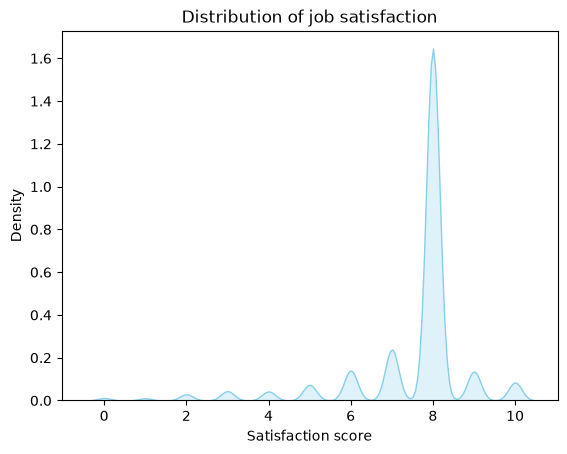

In [23]:
## Write your code here
sns.kdeplot(data=df, x='JobSat', fill=True, color='skyblue')
plt.title('Distribution of job satisfaction')
plt.ylabel('Density')
plt.xlabel('Satisfaction score')
plt.show()

A higher part of the curve means more values are clustered around that area. It doesn't mean every person gave exactly that score.

**One important caution:** The earlier cleaning step filled missing job-satisfaction answers with the most common value. Because so many answers were missing, the shape of this chart may reflect that replacement choice as much as respondents' actual experiences.

### Step 6: Programming Languages Analysis


- Compare the frequency of programming languages in `LanguageHaveWorkedWith` and `LanguageWantToWorkWith`.
- Visualize the overlap or differences using a Venn diagram or a grouped bar chart.

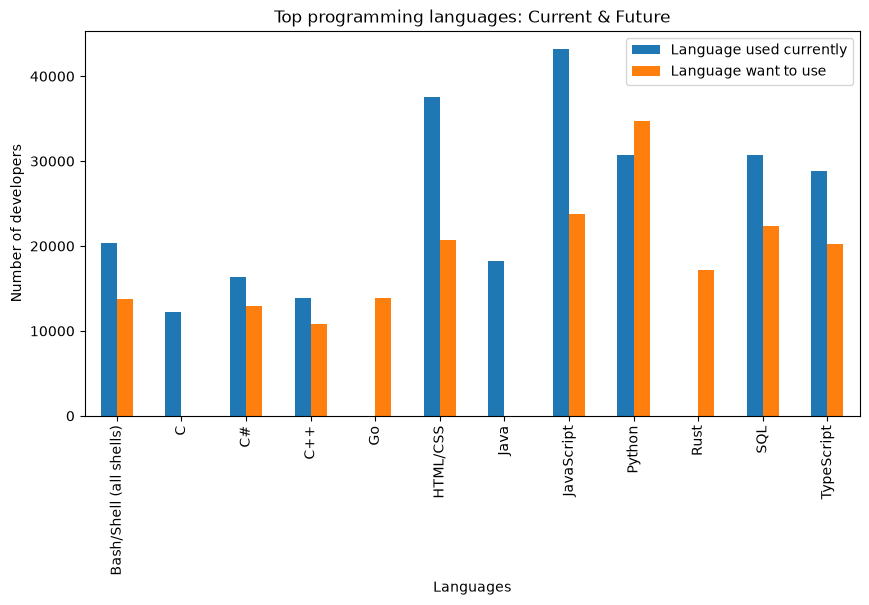

In [25]:
## Write your code here
current_lang = df['LanguageHaveWorkedWith'].str.split(';').explode().value_counts().head(10)
future_lang = df['LanguageWantToWorkWith'].str.split(';').explode().value_counts().head(10)
lang_comparison = pd.DataFrame({'Language used currently': current_lang, 'Language want to use': future_lang}).fillna(0)


lang_comparison.plot(kind='bar', figsize=(10, 5))
plt.title('Top programming languages: Current & Future')
plt.ylabel('Number of developers')
plt.xlabel('Languages')
plt.show()

This comparison looks at two different survey questions: languages respondents say they've worked with, and languages they want to work with. Some people select more than one language. The code separates those answers and counts how many times each language is mentioned.

The grouped chart helps me compare current use with future interest. A language can appear in both groups, and one respondent can contribute to multiple bars. These are mentions in survey answers, not unique developer counts or verified job vacancies.

### Step 7: Analyze Remote Work Trends


- Visualize the distribution of RemoteWork by region using a grouped bar chart or heatmap.


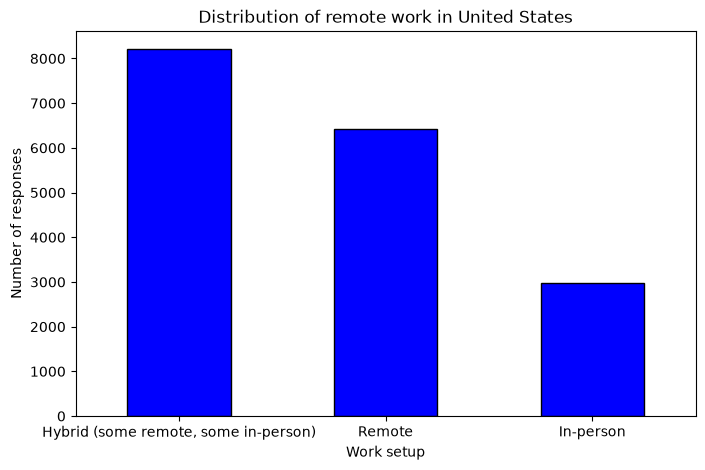

In [27]:
## Write your code here
us_data = df[df['Country'] == 'United States of America']

plt.figure(figsize=(8, 5))
us_data['RemoteWork'].value_counts().plot(kind='bar', color='blue', edgecolor='black')
plt.title('Distribution of remote work in United States')
plt.ylabel('Number of responses')
plt.xlabel('Work setup')
plt.xticks(rotation=0)
plt.show()

For this section, I focus on responses from the United States and compare the reported remote-work arrangements. A bar chart makes it easy to see which category has more responses. But it shows reported arrangements, not necessarily whether respondents prefer remote, hybrid, or in-person work.

The original lab asks about regions, while this code only filters for the United States. So this chart is a single-country distribution, not a comparison across regions. The earlier filling of missing RemoteWork values also affects these counts.

### Step 8: Correlation between Job Satisfaction and Experience


- Analyze the correlation between overall job satisfaction (`JobSat`) and `YearsCodePro`.
- Calculate the Pearson or Spearman correlation coefficient.

This is a question I would naturally want to ask: do people with more professional coding experience tend to report higher satisfaction? The code converts both fields into numbers and calculates a Pearson correlation, which describes the strength of a linear relationship.

In [31]:
## Write your code here
df['YearsCodePro_numeric'] = pd.to_numeric(df['YearsCodePro'], errors='coerce').fillna(0)
df['JobSat_numeric'] = pd.to_numeric(df['JobSat'], errors='coerce').fillna(0)

correlation_value = df['JobSat_numeric'].corr(df['YearsCodePro_numeric'])
print(f"The correlation score between Experience and Job satisfaction is: {correlation_value:.2f}")

The correlation score between Experience and Job satisfaction is: 0.00

**Saved result:** 0.00 (rounded). With this calculation, there is no meaningful linear association visible in the reported coefficient. However, the code also turns non-numeric and missing answers into zero, which can distort the relationship. I wouldn't use this result alone to conclude that experience and satisfaction are unrelated.

### Step 9: Cross-tabulation Analysis (Employment vs. Education Level)


- Analyze the relationship between employment status (`Employment`) and education level (`EdLevel`).
- **Instruction**: Create a cross-tabulation using `pd.crosstab()` and visualize it with a stacked bar plot if possible.

 A cross-tabulation counts the number of survey responses in each combination. The chart focuses on the three most frequent education categories and the five most frequent employment categories. It helps show where responses are concentrated, but the groups aren't all the same size.

/tmp/ipykernel_299/264018308.py:14: UserWarning: Tight layout not applied. The left and right margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()

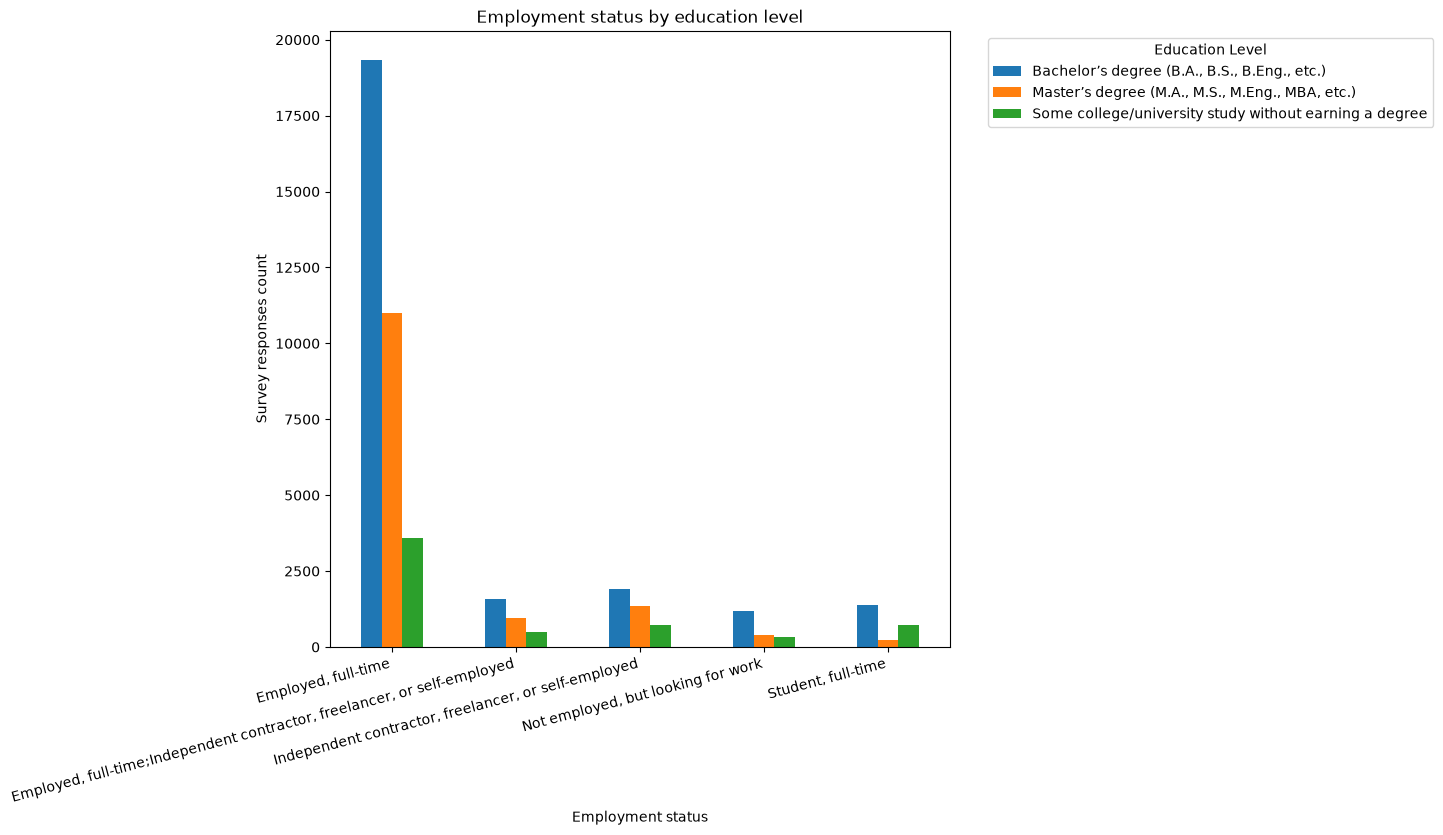

In [59]:
## Write your code here
top_edu = df['EdLevel'].value_counts().nlargest(3).index
top_emp = df['Employment'].value_counts().nlargest(5).index
filtered_df = df[df['EdLevel'].isin(top_edu) & df['Employment'].isin(top_emp)]
clean_matrix = pd.crosstab(filtered_df['Employment'], filtered_df['EdLevel'])


clean_matrix.plot(kind='bar', figsize=(8, 8))
plt.title('Employment status by education level')
plt.xlabel('Employment status')
plt.ylabel('Survey responses count')
plt.legend(title='Education Level', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.xticks(rotation=15, ha='right')
plt.tight_layout()
plt.show()

How I'd improve the comparison: Looking at percentages within each education level would make it easier to compare groups fairly. The current chart shows counts, not employment probabilities.

### Step 10: Export Cleaned Data


- Save the cleaned dataset to a new CSV file for further use or sharing.


In [63]:
## Write your code here
df.to_csv('explored_survey_data.csv', index=False)
print("Success!")

Success!

### Key Findings and Takeaways
- The saved dataset contains 65,437 survey responses across 114 fields.
- Missing answers are a major consideration, particularly for job satisfaction and compensation. Filling them automatically can change the patterns we see.
- Employment counts and programming-language mentions help describe the survey sample, but they should not be treated as population-wide or labor-market statistics.
- The US remote-work chart describes working arrangements among selected survey respondents; it doesn't measure preferences.
- The saved correlation between professional experience and job satisfaction rounds to 0.00, but the handling of missing and non-numeric values limits its interpretation.
- Education and employment comparisons would be clearer with within-group percentages rather than counts alone.

### Limitations and Improvements
If I extended this work beyond the guided lab, I would first examine why data is missing, compare distributions before and after filling values, keep unknown answers distinct from genuine zeros, and use normalized percentages when comparing groups of different sizes. I would also verify the survey's coverage before making broader claims.

### Skills Demonstrated
- Data exploration: Inspecting columns, data types, and response frequencies.
- Data preparation: Identifying missing values and documenting how replacements affect interpretation.
- Data visualization: Density plots, grouped bar charts, and categorical comparisons.
- Statistical thinking: Reading correlation carefully and separating observed patterns from causal claims.
- Communication: Explaining what charts mean in straightforward language.

*Attribution: Original lab, source data, logo, and instructional content are from IBM Skills Network. The additional explanations are personalized portfolio documentation.*

### Summary:


In this lab, you practiced key skills in exploratory data analysis, including:
- Examining the structure and content of the Stack Overflow survey dataset to understand its variables and data types.
- Identifying and addressing missing data to ensure the dataset's quality and completeness.
- Summarizing and visualizing key variables such as job satisfaction, programming languages, and remote work trends.
- Analyzing relationships in the data using techniques like:
    - Comparing programming languages respondents have worked with versus those they want to work with.
    - Exploring remote work preferences by region.
- Investigating correlations between professional coding experience and job satisfaction.
- Performing cross-tabulations to analyze relationships between employment status and education levels.

## Authors:
Ayushi Jain


### Other Contributors:
Rav Ahuja
Lakshmi Holla
Malika


Copyright © IBM Corporation. All rights reserved.
